[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/notebooks/07_svm.ipynb)

<div dir="rtl">

# جلسه ۷: ماشین بردار پشتیبان (SVM)

**اهداف این جلسه**

- درک ایده‌ی **حاشیه‌ی بیشینه (Maximum Margin)** و بردارهای پشتیبان
- تفاوت حاشیه‌ی سخت و نرم و نقش ابرپارامتر `C`
- آشنایی با **ترفند کرنل (Kernel Trick)** برای مرزهای غیرخطی
- نقش ابرپارامتر `gamma` در کرنل RBF
- رگرسیون با بردار پشتیبان (SVR)
- اینکه SVM کجا مناسب است و کجا نه

</div>

<div dir="rtl">

## ۱. ایده‌ی اصلی: بزرگ‌ترین حاشیه

وقتی دو کلاس با یک خط قابل جدا شدن‌اند، بی‌نهایت خط جداکننده وجود دارد. کدام بهتر است؟ SVM خطی را انتخاب می‌کند که **بیشترین فاصله** را از نزدیک‌ترین نقاط هر دو کلاس داشته باشد. این فاصله را **حاشیه (margin)** می‌نامیم. شهود: مرزی که از هر دو کلاس فاصله‌ی زیادی دارد، روی داده‌ی جدید هم احتمالاً درست‌تر عمل می‌کند.

نقاطی که دقیقاً روی لبه‌ی حاشیه قرار می‌گیرند، **بردارهای پشتیبان (Support Vectors)** نام دارند. نکته‌ی جالب: مرز تصمیم **فقط** به همین چند نقطه بستگی دارد. اگر بقیه‌ی نقاط را حذف کنیم، مرز تغییری نمی‌کند.

</div>

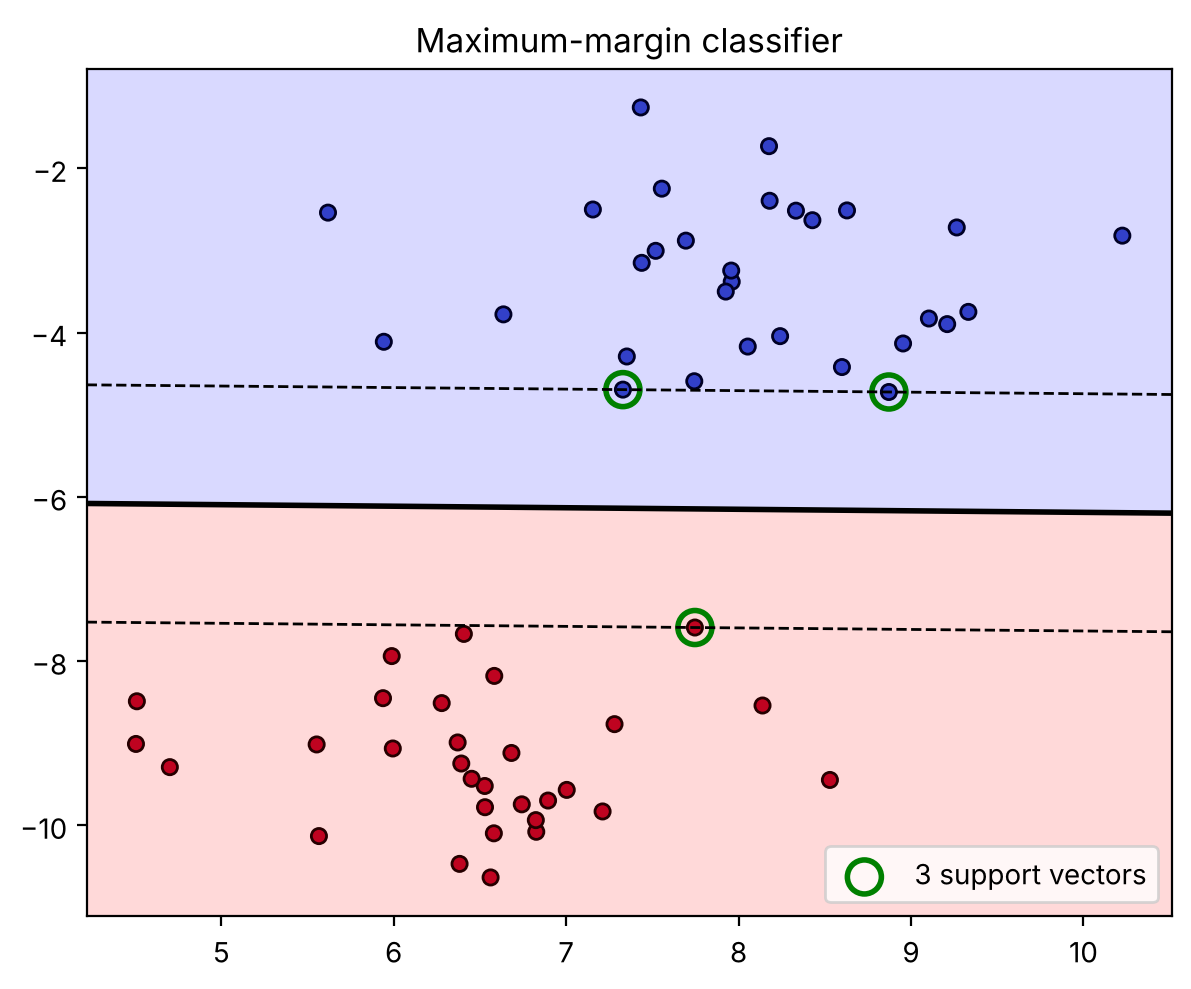

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.datasets import make_blobs, make_moons

def plot_svm(model, X, y, ax, title=""):
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=30)
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    xx, yy = np.meshgrid(np.linspace(*xlim, 300), np.linspace(*ylim, 300))
    Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-100, 0, 100], alpha=0.15, colors=["blue", "red"])
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=[1, 2, 1])
    sv = model.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=150, facecolors="none", edgecolors="green", linewidths=2,
               label=f"{len(sv)} support vectors")
    ax.set_title(title)
    ax.legend(loc="lower right")

X, y = make_blobs(n_samples=60, centers=2, cluster_std=0.9, random_state=6)
svm_linear = SVC(kernel="linear", C=1000).fit(X, y)

fig, ax = plt.subplots(figsize=(7, 5.5))
plot_svm(svm_linear, X, y, ax, "Maximum-margin classifier")
plt.show()

<div dir="rtl">

خط ممتد مرز تصمیم و خط‌چین‌ها لبه‌های حاشیه‌اند. نقاط دایره‌دار سبز، بردارهای پشتیبان هستند.

### فرمول‌بندی ریاضی

مرز تصمیم $\mathbf{w}^\top\mathbf{x} + b = 0$ است و پهنای حاشیه برابر $\frac{2}{\|\mathbf{w}\|}$. پس بیشینه کردن حاشیه یعنی کمینه کردن $\|\mathbf{w}\|$، به شرطی که همه‌ی نقاط درست و بیرون از حاشیه طبقه‌بندی شوند (با برچسب‌های $\pm 1$):

</div>

$$\min_{\mathbf{w}, b} \frac{1}{2}\|\mathbf{w}\|^2 \quad \text{subject to} \quad y^{(i)}\left(\mathbf{w}^\top\mathbf{x}^{(i)} + b\right) \ge 1 \quad \forall i$$

<div dir="rtl">

## ۲. حاشیه‌ی نرم و ابرپارامتر C

داده‌ی واقعی معمولاً نویز دارد و کاملاً جداپذیر نیست. **حاشیه‌ی نرم (Soft Margin)** اجازه می‌دهد بعضی نقاط داخل حاشیه یا حتی در سمت اشتباه قرار بگیرند، ولی برای هر تخطی جریمه‌ای در نظر می‌گیرد:

</div>

$$\min_{\mathbf{w}, b} \frac{1}{2}\|\mathbf{w}\|^2 + C \sum_{i=1}^{m} \max\left(0,\ 1 - y^{(i)}\left(\mathbf{w}^\top\mathbf{x}^{(i)} + b\right)\right)$$

<div dir="rtl">

عبارت داخل جمع، **Hinge Loss** نام دارد. ابرپارامتر `C` تعادل بین «حاشیه‌ی پهن» و «خطای کم روی داده‌ی آموزش» را تعیین می‌کند:

- `C` **بزرگ**: تخطی‌ها گران‌اند، پس حاشیه باریک می‌شود تا همه‌ی نقاط درست طبقه‌بندی شوند. خطر **بیش‌برازش**.
- `C` **کوچک**: حاشیه پهن‌تر است و چند خطا تحمل می‌شود. مدل ساده‌تر و مقاوم‌تر در برابر نویز، ولی خطر **کم‌برازش**.

`C` نقشی شبیه به معکوس $\alpha$ در منظم‌سازی جلسه‌ی ۴ دارد.

</div>

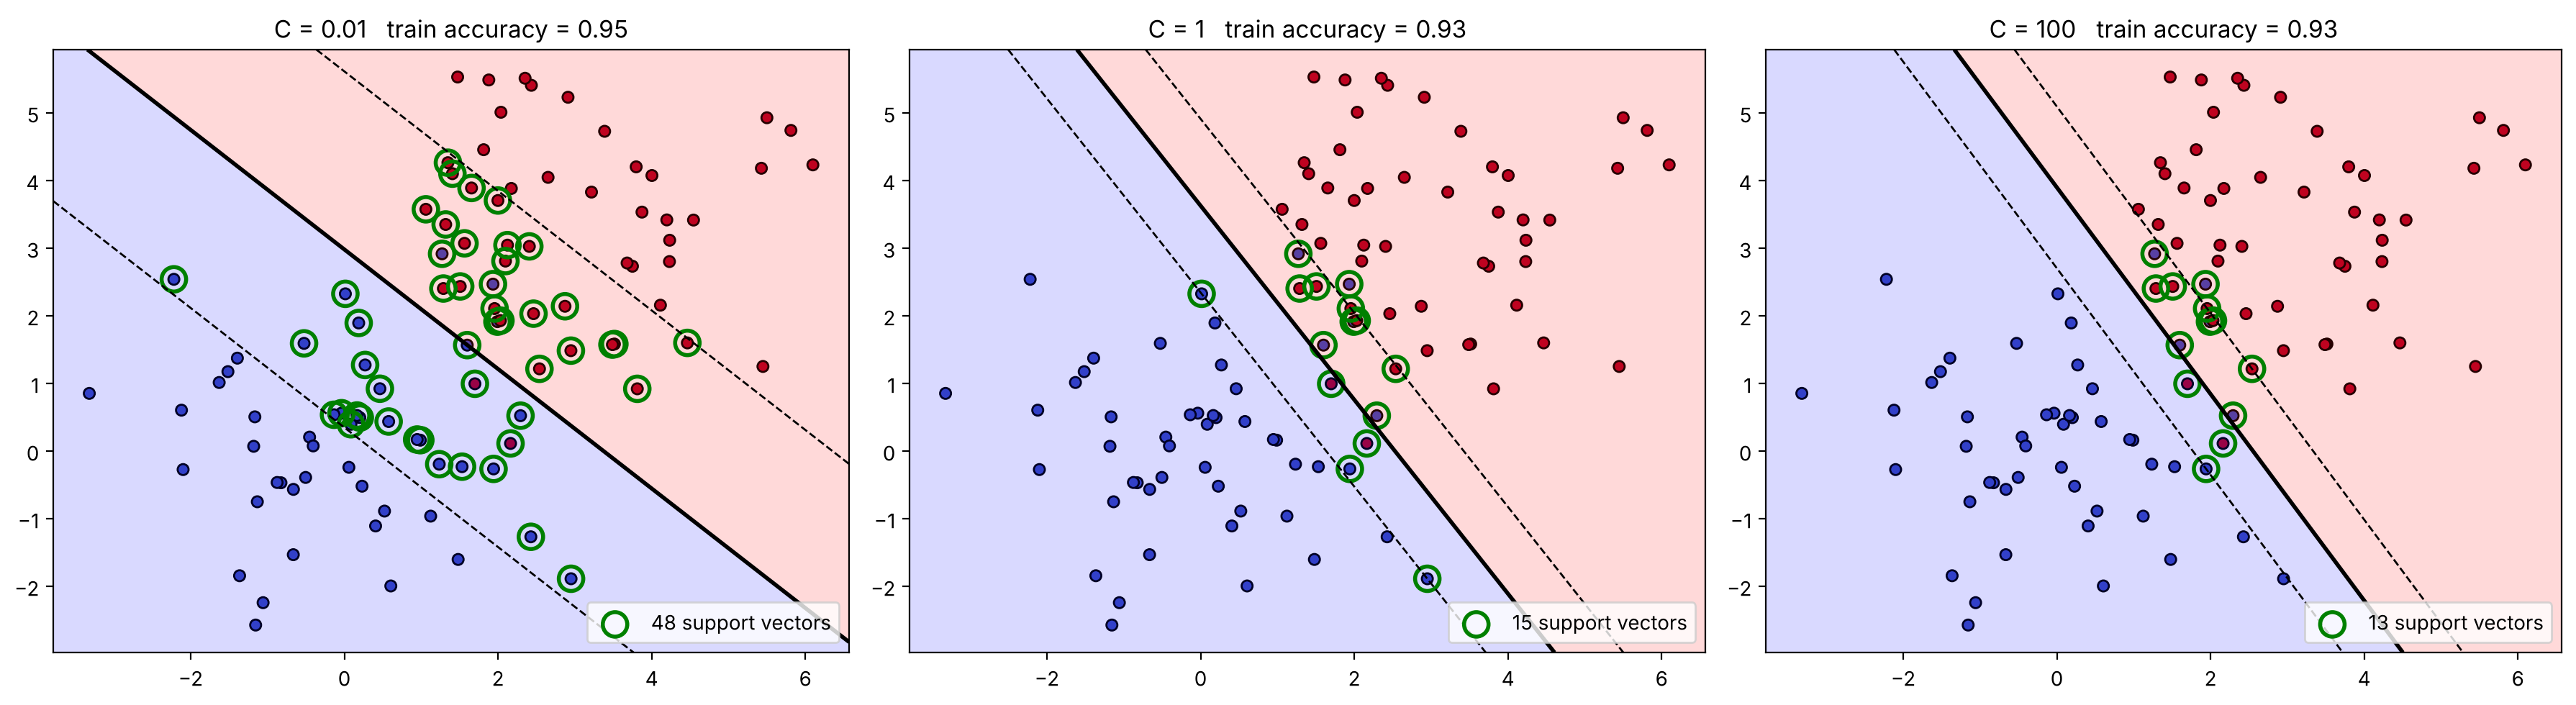

In [2]:
X, y = make_blobs(n_samples=100, centers=[(0, 0), (3, 3)], cluster_std=1.3, random_state=0)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, C in zip(axes, [0.01, 1, 100]):
    model = SVC(kernel="linear", C=C).fit(X, y)
    plot_svm(model, X, y, ax, f"C = {C}   train accuracy = {model.score(X, y):.2f}")
plt.tight_layout()
plt.show()

<div dir="rtl">

با `C` کوچک، حاشیه بسیار پهن است و تعداد زیادی از نقاط بردار پشتیبان‌اند. با افزایش `C`، حاشیه باریک‌تر می‌شود، بردارهای پشتیبان کمتر می‌شوند و نقاط کمتری اجازه دارند داخل حاشیه قرار بگیرند. در این داده، دقت آموزش در هر سه حالت تقریباً یکسان است، ولی جهت و جای مرز تغییر کرده است. `C` مناسب را باید با اعتبارسنجی پیدا کرد.

## ۳. مرزهای غیرخطی و ترفند کرنل

وقتی داده با خط جدا نمی‌شود چه کنیم؟ یک راه، مثل رگرسیون چندجمله‌ای، نگاشت داده به **فضای بالاتر** است؛ جایی که داده خطی جداپذیر می‌شود. مثلاً نقاط یک‌بعدی که با هیچ نقطه‌ای جدا نمی‌شوند، با اضافه کردن ویژگی $x^2$ با یک خط قابل جداسازی‌اند:

</div>

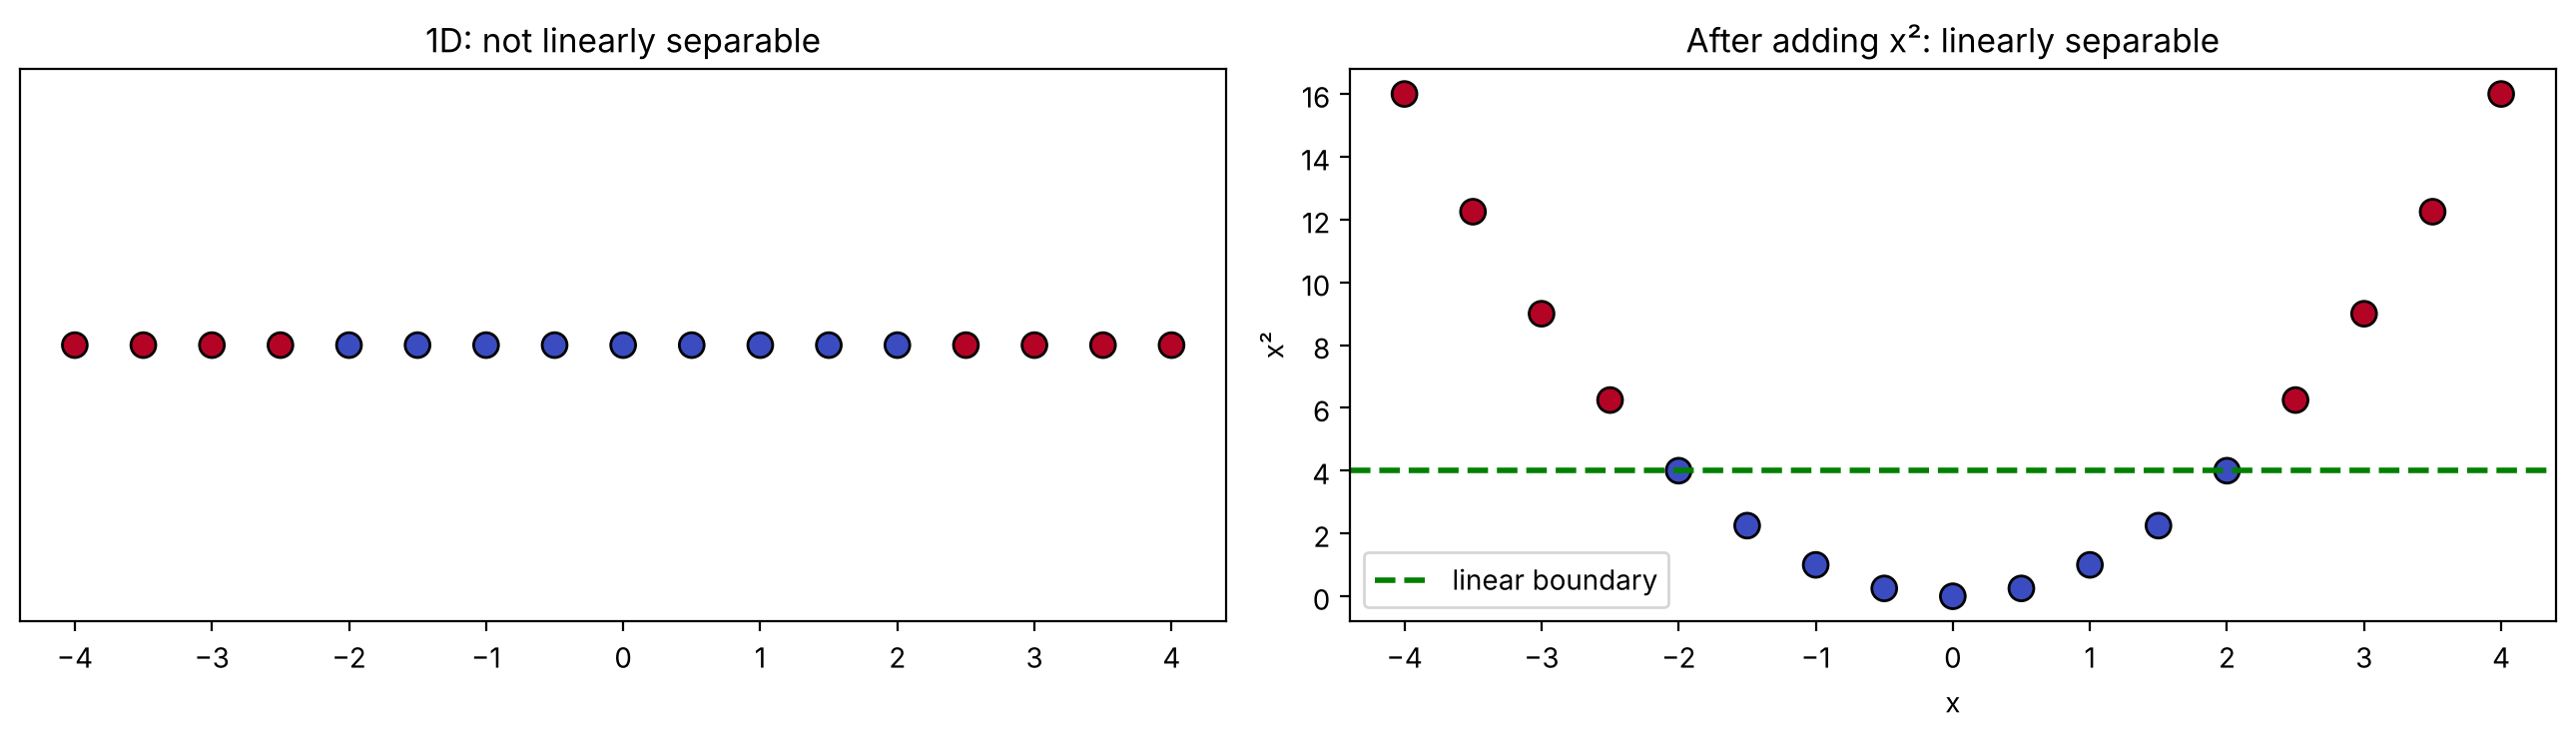

In [3]:
x1 = np.linspace(-4, 4, 17)
y1 = (np.abs(x1) > 2).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].scatter(x1, np.zeros_like(x1), c=y1, cmap="coolwarm", s=80, edgecolor="k")
axes[0].set_title("1D: not linearly separable")
axes[0].set_yticks([])
axes[1].scatter(x1, x1 ** 2, c=y1, cmap="coolwarm", s=80, edgecolor="k")
axes[1].axhline(4, color="green", linestyle="--", linewidth=2, label="linear boundary")
axes[1].set_xlabel("x")
axes[1].set_ylabel("x²")
axes[1].set_title("After adding x²: linearly separable")
axes[1].legend()
plt.tight_layout()
plt.show()

<div dir="rtl">

مشکل: ساختن صریح ویژگی‌های درجه‌ی بالا برای داده‌ی پرویژگی بسیار پرهزینه است. **ترفند کرنل** این مشکل را حل می‌کند. الگوریتم SVM فقط به **ضرب داخلی** بین نقاط نیاز دارد و یک **تابع کرنل** $K(\mathbf{x}, \mathbf{z})$ این ضرب داخلی را در فضای بالا مستقیماً حساب می‌کند، **بدون اینکه نگاشت را واقعاً انجام دهد**.

کرنل‌های رایج:

</div>

$$\text{Polynomial: } K(\mathbf{x}, \mathbf{z}) = \left(\gamma\, \mathbf{x}^\top\mathbf{z} + r\right)^d \qquad \text{RBF (Gaussian): } K(\mathbf{x}, \mathbf{z}) = \exp\left(-\gamma \|\mathbf{x} - \mathbf{z}\|^2\right)$$

<div dir="rtl">

کرنل **RBF** معمولاً بهترین انتخاب پیش‌فرض است. می‌توان آن را این‌طور تصور کرد: هر نقطه‌ی آموزشی یک «تپه‌ی گوسی» دور خودش می‌سازد و مرز تصمیم از جمع وزن‌دار این تپه‌ها به دست می‌آید.

</div>

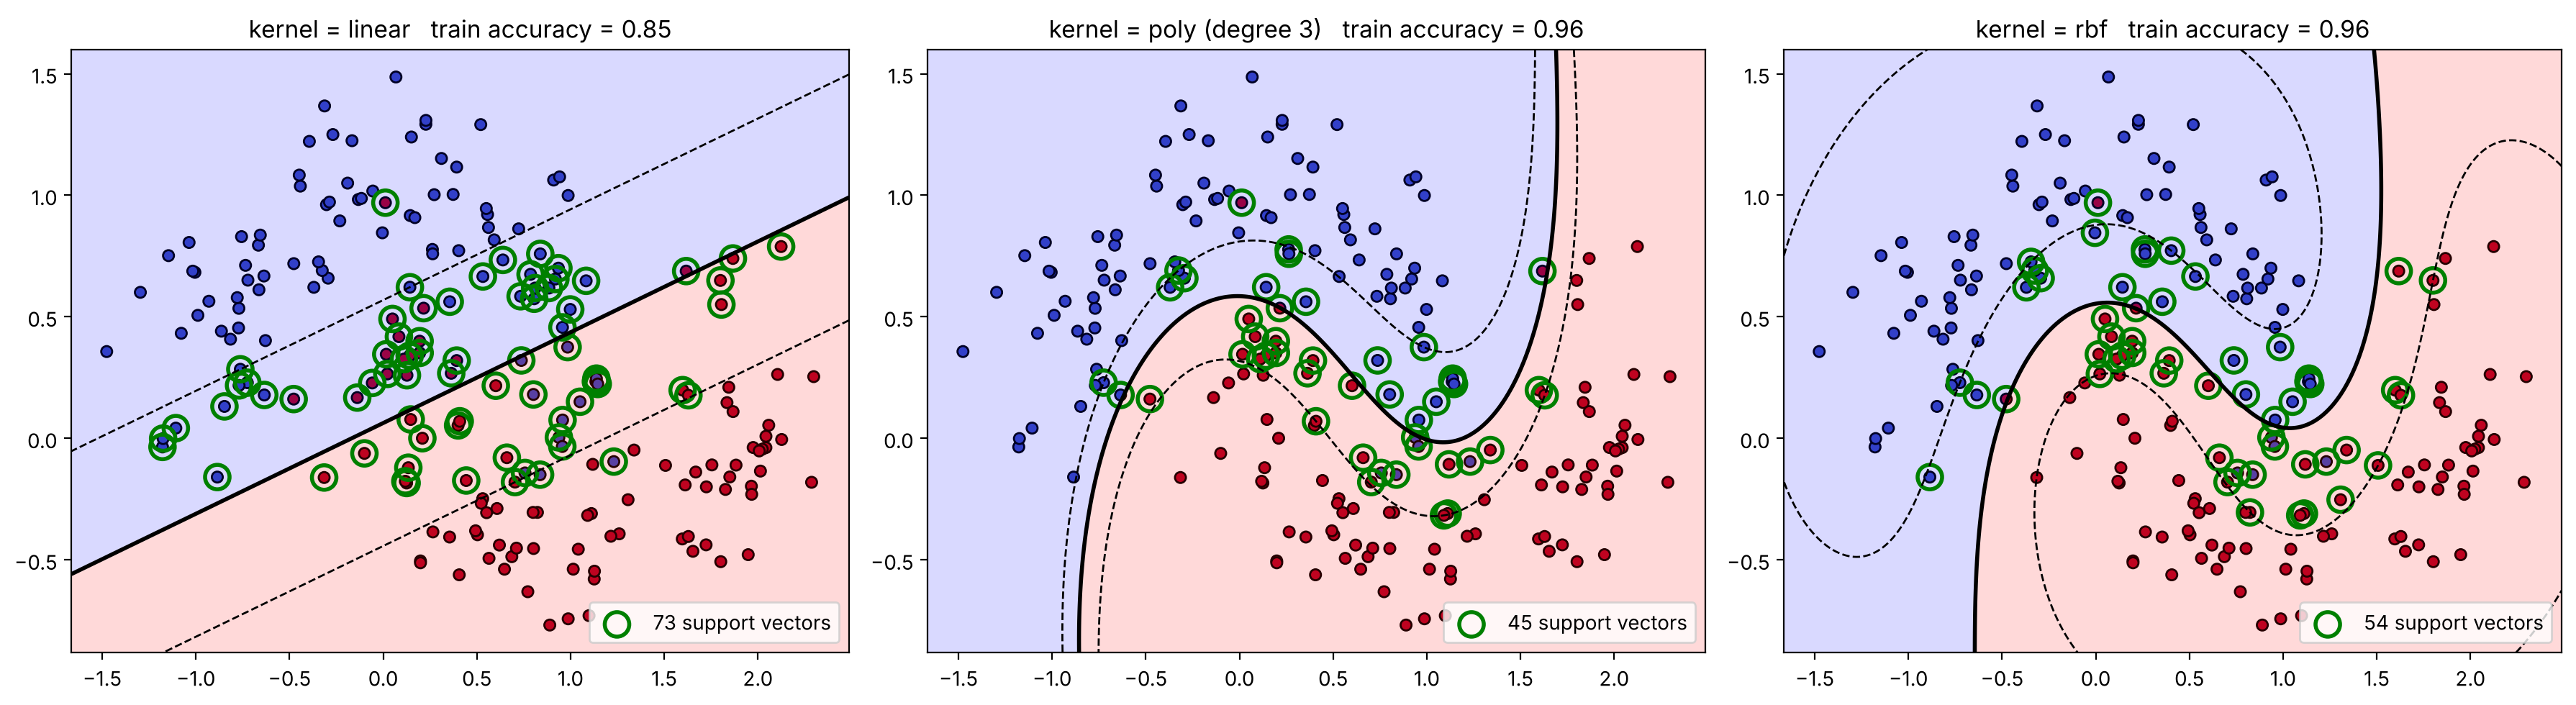

In [4]:
X, y = make_moons(n_samples=200, noise=0.2, random_state=42)

kernels = [("linear", SVC(kernel="linear", C=1)),
           ("poly (degree 3)", SVC(kernel="poly", degree=3, coef0=1, C=1)),
           ("rbf", SVC(kernel="rbf", C=1))]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, model) in zip(axes, kernels):
    model.fit(X, y)
    plot_svm(model, X, y, ax, f"kernel = {name}   train accuracy = {model.score(X, y):.2f}")
plt.tight_layout()
plt.show()

<div dir="rtl">

## ۴. ابرپارامتر gamma در کرنل RBF

`gamma` تعیین می‌کند هر نقطه تا چه فاصله‌ای اثر دارد:

- `gamma` **کوچک**: تپه‌ها پهن‌اند و هر نقطه روی ناحیه‌ی بزرگی اثر دارد؛ مرز نرم و ساده است.
- `gamma` **بزرگ**: تپه‌ها باریک‌اند و هر نقطه فقط روی اطراف نزدیک خودش اثر دارد؛ مرز پیچیده می‌شود و دور تک‌تک نقاط می‌پیچد. **بیش‌برازش**.

`C` و `gamma` با هم پیچیدگی مدل را کنترل می‌کنند و باید **با هم** تنظیم شوند:

</div>

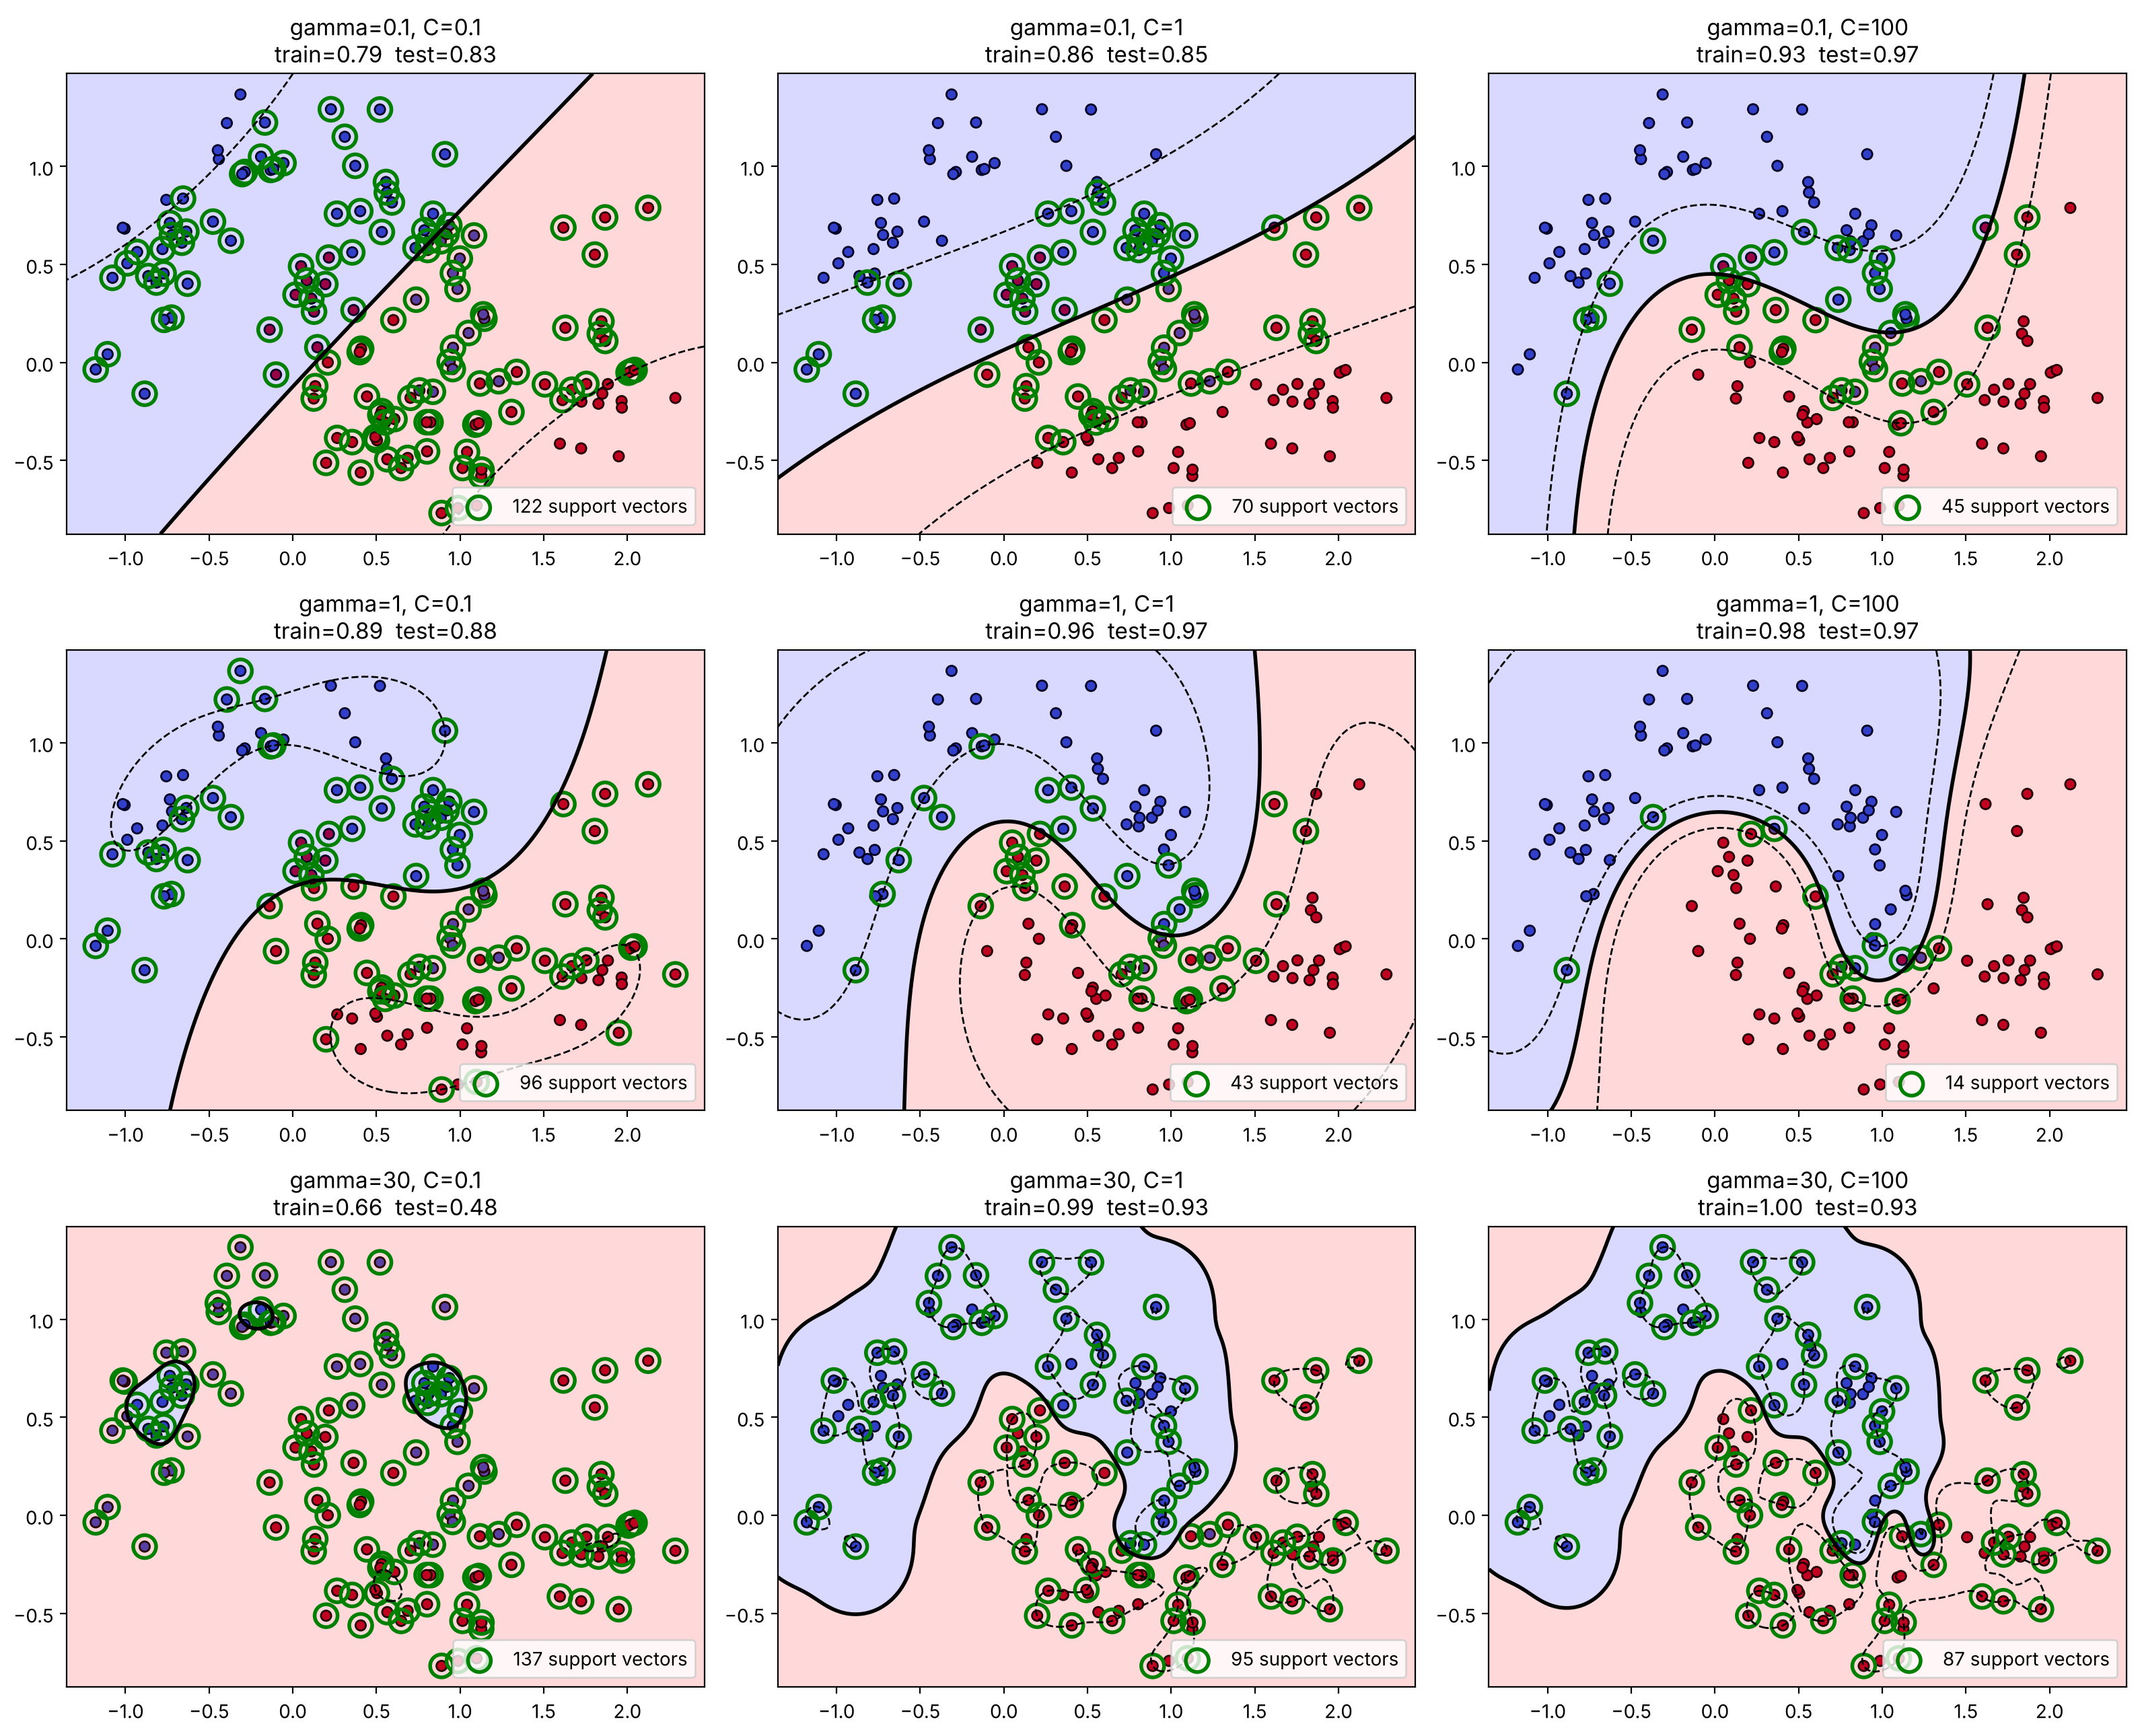

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
for i, gamma in enumerate([0.1, 1, 30]):
    for j, C in enumerate([0.1, 1, 100]):
        model = SVC(kernel="rbf", gamma=gamma, C=C).fit(X_train, y_train)
        plot_svm(model, X_train, y_train, axes[i, j],
                 f"gamma={gamma}, C={C}\ntrain={model.score(X_train, y_train):.2f}  test={model.score(X_test, y_test):.2f}")
plt.tight_layout()
plt.show()

<div dir="rtl">

- گوشه‌ی بالا-چپ (`gamma` و `C` کوچک): کم‌برازش.
- گوشه‌ی پایین-راست (`gamma` و `C` بزرگ): بیش‌برازش شدید؛ دقت آموزش بالا ولی دقت آزمون پایین‌تر.
- ترکیب‌های میانی بهترین تعمیم را دارند.

## ۵. SVM روی داده‌ی واقعی: مقیاس‌بندی و جستجوی ابرپارامتر

SVM، مثل k-NN، به **مقیاس ویژگی‌ها** بسیار حساس است. با داده‌ی سرطان سینه‌ی جلسه‌ی ۵ امتحان می‌کنیم و بهترین `C` و `gamma` را با **جستجوی شبکه‌ای (Grid Search)** و اعتبارسنجی متقابل پیدا می‌کنیم. جزئیات `GridSearchCV` در جلسه‌ی ۱۰ آمده است.

</div>

In [6]:
from sklearn.datasets import load_breast_cancer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, GridSearchCV

cancer = load_breast_cancer()
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    cancer.data, cancer.target, test_size=0.25, stratify=cancer.target, random_state=42)

no_scale = cross_val_score(SVC(), Xc_train, yc_train, cv=5).mean()
with_scale = cross_val_score(make_pipeline(StandardScaler(), SVC()), Xc_train, yc_train, cv=5).mean()
print(f"SVM without scaling: {no_scale:.3f}")
print(f"SVM with scaling:    {with_scale:.3f}")

SVM without scaling: 0.908
SVM with scaling:    0.965


In [7]:
pipe = make_pipeline(StandardScaler(), SVC())
param_grid = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": ["scale", 0.001, 0.01, 0.1],
}
grid = GridSearchCV(pipe, param_grid, cv=5, n_jobs=-1)
grid.fit(Xc_train, yc_train)

print("Best parameters:", grid.best_params_)
print(f"Best CV accuracy: {grid.best_score_:.3f}")
print(f"Test accuracy:    {grid.score(Xc_test, yc_test):.3f}")

Best parameters: {'svc__C': 10, 'svc__gamma': 0.001}
Best CV accuracy: 0.977
Test accuracy:    0.979


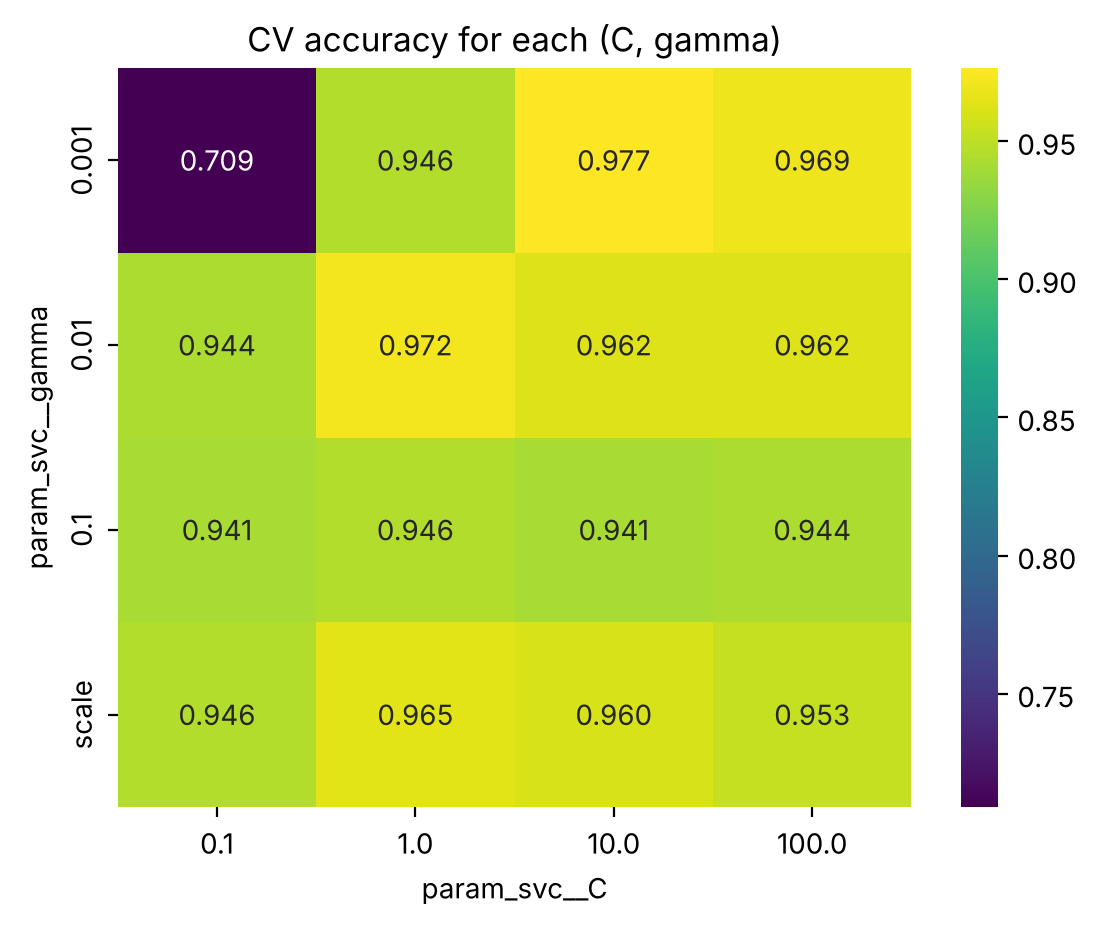

In [8]:
results = pd.DataFrame(grid.cv_results_)
heat = results.pivot_table(index="param_svc__gamma", columns="param_svc__C", values="mean_test_score")
import seaborn as sns
sns.heatmap(heat, annot=True, fmt=".3f", cmap="viridis")
plt.title("CV accuracy for each (C, gamma)")
plt.show()

<div dir="rtl">

### احتمال در SVM

SVM به‌طور طبیعی احتمال تولید نمی‌کند؛ فقط فاصله از مرز (`decision_function`) را می‌دهد. برای تبدیل این فاصله به احتمال، مدل را داخل `CalibratedClassifierCV` قرار می‌دهیم که با اعتبارسنجی متقابل یک نگاشت به احتمال یاد می‌گیرد؛ آموزش کندتر می‌شود. (در نسخه‌های قدیمی‌تر scikit-learn از `SVC(probability=True)` استفاده می‌شد.) برای منحنی ROC، خود `decision_function` کافی است.

## ۶. رگرسیون با بردار پشتیبان (SVR)

ایده‌ی SVM برای رگرسیون هم قابل استفاده است. SVR تلاش می‌کند تا جای ممکن نقاط داخل یک **لوله** به پهنای $\varepsilon$ حول تابع پیش‌بینی قرار بگیرند. خطاهای داخل لوله جریمه نمی‌شوند و فقط نقاط بیرون آن (بردارهای پشتیبان) در تعیین مدل نقش دارند.

</div>

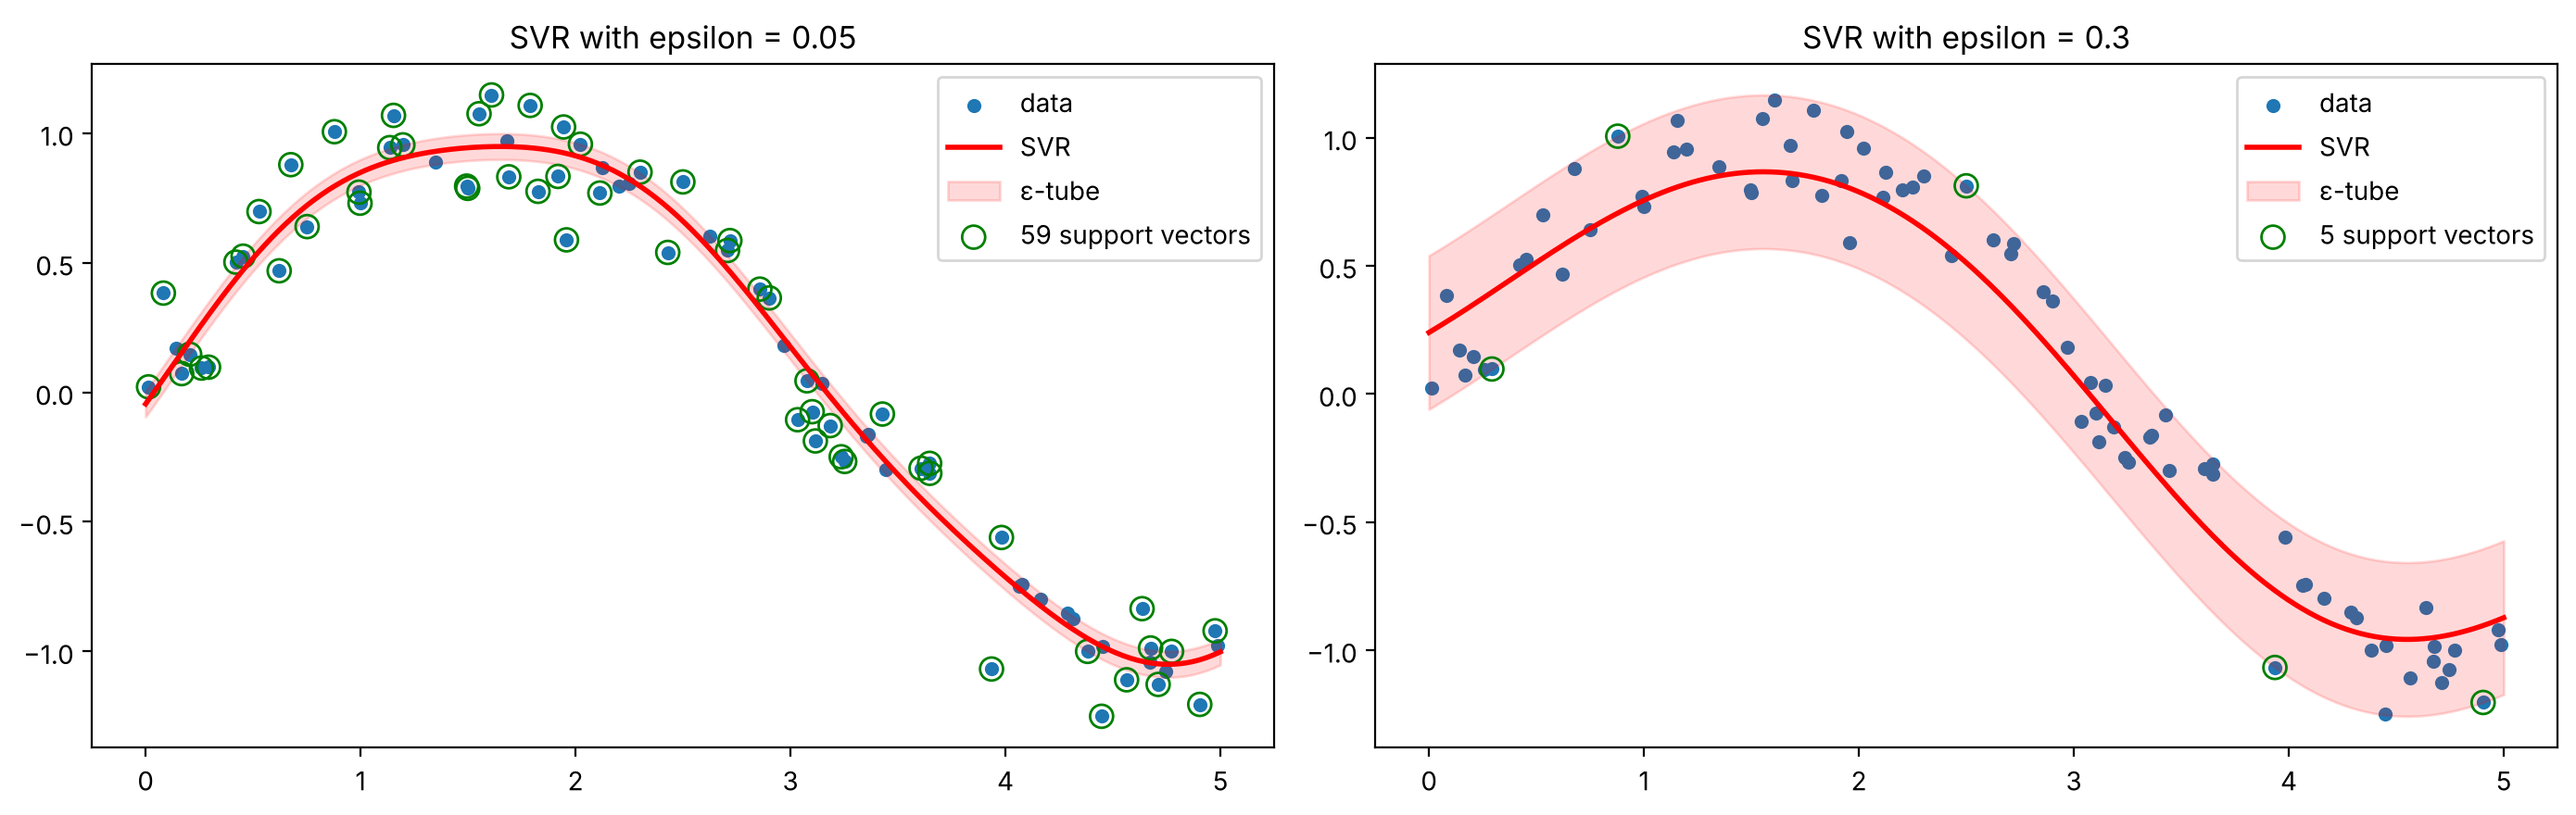

In [9]:
from sklearn.svm import SVR

rng = np.random.default_rng(0)
X_r = np.sort(5 * rng.random((80, 1)), axis=0)
y_r = np.sin(X_r).ravel() + rng.normal(0, 0.15, 80)
x_plot = np.linspace(0, 5, 300).reshape(-1, 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, eps in zip(axes, [0.05, 0.3]):
    svr = SVR(kernel="rbf", C=10, epsilon=eps).fit(X_r, y_r)
    pred = svr.predict(x_plot)
    ax.scatter(X_r, y_r, s=20, label="data")
    ax.plot(x_plot, pred, color="red", linewidth=2, label="SVR")
    ax.fill_between(x_plot.ravel(), pred - eps, pred + eps, color="red", alpha=0.15, label="ε-tube")
    ax.scatter(X_r[svr.support_], y_r[svr.support_], s=80, facecolors="none", edgecolors="green",
               label=f"{len(svr.support_)} support vectors")
    ax.set_title(f"SVR with epsilon = {eps}")
    ax.legend()
plt.tight_layout()
plt.show()

<div dir="rtl">

با $\varepsilon$ بزرگ‌تر، لوله پهن‌تر است، نقاط بیشتری داخل آن قرار می‌گیرند و تعداد بردارهای پشتیبان کم می‌شود؛ مدل ساده‌تر می‌شود.

## ۷. SVM کجا مناسب است؟

| مزایا | معایب |
|---|---|
| عملکرد بسیار خوب روی داده‌های کوچک و متوسط | آموزش کند برای داده‌ی بزرگ (پیچیدگی تقریباً بین $O(m^2)$ و $O(m^3)$) |
| مؤثر در ابعاد بالا (مثل متن) | حساس به مقیاس ویژگی‌ها |
| با کرنل، مرزهای غیرخطی پیچیده | انتخاب کرنل و تنظیم `C` و `gamma` لازم است |
| حافظه‌ی کم در پیش‌بینی (فقط بردارهای پشتیبان) | احتمال مستقیم تولید نمی‌کند و تفسیر آن سخت است |

برای داده‌های بزرگ (بیش از چند ده هزار نمونه) و مسائل خطی، از `LinearSVC` یا `SGDClassifier(loss="hinge")` استفاده کنید که بسیار سریع‌ترند.

## ۸. جمع‌بندی

- SVM مرزی با **بیشترین حاشیه** پیدا می‌کند و فقط به بردارهای پشتیبان وابسته است.
- `C` تعادل بین حاشیه‌ی پهن و خطای آموزش را کنترل می‌کند.
- ترفند کرنل، مرزهای غیرخطی را بدون ساختن صریح ویژگی‌های جدید ممکن می‌کند؛ RBF انتخاب پیش‌فرض خوبی است.
- `C` و `gamma` را با هم و با اعتبارسنجی متقابل تنظیم کنید و همیشه قبل از SVM مقیاس‌بندی انجام دهید.

## ۹. تمرین

1. در شکل بخش ۱، یکی از نقاطی را که بردار پشتیبان **نیست** حذف کنید و مدل را دوباره آموزش دهید. مرز تغییر می‌کند؟ حالا یک بردار پشتیبان را حذف کنید.
2. روی داده‌ی moons، `SVC(kernel="poly")` را با درجه‌های ۲، ۳ و ۵ امتحان کنید و مرز تصمیم را رسم کنید.
3. روی داده‌ی Wine، SVM خطی و RBF را با اعتبارسنجی متقابل مقایسه کنید.
4. روی داده‌ی مسکن جلسه‌ی ۳، `SVR` را با مقیاس‌بندی امتحان کنید. (راهنمایی: برای سرعت، ابتدا روی ۵۰۰۰ نمونه آموزش دهید.) با رگرسیون خطی مقایسه کنید.

</div>